<a href="https://colab.research.google.com/github/dhruvizaveri08/credit-risk-analysis/blob/main/01_credit_risk_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np

# Make the results reproducible
np.random.seed(42)

# Number of synthetic loan applicants
n = 1000

# Create sample borrower data
df = pd.DataFrame({
    "customer_id": range(1, n + 1),
    "age": np.random.randint(21, 66, n),
    "annual_income": np.random.randint(200000, 2000000, n),
    "credit_score": np.random.randint(300, 851, n),
    "employment_years": np.random.randint(0, 31, n),
    "loan_amount": np.random.randint(25000, 1000000, n),
    "debt_to_income_ratio": np.round(
        np.random.uniform(0.05, 0.75, n), 2
    )
})

# Create a synthetic default outcome for practice.
# These rules are illustrative, not a real credit-risk model.
risk_score = (
    (df["credit_score"] < 580).astype(int)
    + (df["debt_to_income_ratio"] > 0.45).astype(int)
    + (df["loan_amount"] > df["annual_income"] * 0.5).astype(int)
)

df["default"] = (risk_score >= 2).astype(int)

# Display the first five rows
print("Dataset created successfully!")
display(df.head())


Dataset created successfully!


,customer_id,age,annual_income,credit_score,employment_years,loan_amount,debt_to_income_ratio,default
0,1,59,879290,608,20,524797,0.10,0
1,2,49,699097,587,16,183763,0.54,0
2,3,35,849789,606,29,627248,0.32,0
3,4,63,1396632,848,9,895820,0.63,1
4,5,28,1262636,651,10,47601,0.51,0


In [ ]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and missing values:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nDefault distribution:")
display(df["default"].value_counts().rename(
    index={0: "No synthetic default", 1: "Synthetic default"}
))


Dataset shape: (1000, 8)

Column names:
['customer_id', 'age', 'annual_income', 'credit_score', 'employment_years', 'loan_amount', 'debt_to_income_ratio', 'default']

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           1000 non-null   int64  
 1   age                   1000 non-null   int64  
 2   annual_income         1000 non-null   int64  
 3   credit_score          1000 non-null   int64  
 4   employment_years      1000 non-null   int64  
 5   loan_amount           1000 non-null   int64  
 6   debt_to_income_ratio  1000 non-null   float64
 7   default               1000 non-null   int64  
dtypes: float64(1), int64(7)
memory usage: 62.6 KB

Summary statistics:


,customer_id,age,annual_income,credit_score,employment_years,loan_amount,debt_to_income_ratio,default
count,1000.000000,1000.000000,1.000000e+03,1000.000000,1000.00000,1000.000000,1000.00000,1000.000000
mean,500.500000,43.000000,1.114462e+06,580.861000,14.89000,512741.652000,0.39677,0.442000
std,288.819436,12.945562,5.050265e+05,156.410236,8.83776,278862.979584,0.20126,0.496873
min,1.000000,21.000000,2.001260e+05,300.000000,0.00000,27187.000000,0.05000,0.000000
25%,250.750000,32.000000,6.908912e+05,448.000000,7.00000,288476.500000,0.22750,0.000000
50%,500.500000,44.000000,1.121060e+06,582.500000,15.00000,505275.500000,0.39000,0.000000
75%,750.250000,54.000000,1.508235e+06,718.000000,22.00000,757499.500000,0.57000,1.000000
max,1000.000000,65.000000,1.998870e+06,850.000000,30.00000,999208.000000,0.75000,1.000000



Default distribution:


,count
default,
No synthetic default,558
Synthetic default,442


In [ ]:

# PART 1: Inspect the dataset

print("Dataset dimensions:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)


Dataset dimensions: (1000, 8)

First 5 rows:


,customer_id,age,annual_income,credit_score,employment_years,loan_amount,debt_to_income_ratio,default
0,1,59,879290,608,20,524797,0.10,0
1,2,49,699097,587,16,183763,0.54,0
2,3,35,849789,606,29,627248,0.32,0
3,4,63,1396632,848,9,895820,0.63,1
4,5,28,1262636,651,10,47601,0.51,0



Column names:
['customer_id', 'age', 'annual_income', 'credit_score', 'employment_years', 'loan_amount', 'debt_to_income_ratio', 'default']

Data types:
customer_id               int64
age                       int64
annual_income             int64
credit_score              int64
employment_years          int64
loan_amount               int64
debt_to_income_ratio    float64
default                   int64
dtype: object


In [ ]:

# PART 2: Missing-value check

missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values in each column:


,0
customer_id,0
age,0
annual_income,0
credit_score,0
employment_years,0
loan_amount,0
debt_to_income_ratio,0
default,0



Total missing values: 0


In [ ]:

# Check for fully duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Check whether customer IDs are duplicated
print("Duplicate customer IDs:",
      df["customer_id"].duplicated().sum())


Duplicate rows: 0
Duplicate customer IDs: 0


In [ ]:

# PART 3: Validate key numerical fields

checks = {
    "Age below 18": (df["age"] < 18).sum(),
    "Non-positive annual income": (df["annual_income"] <= 0).sum(),
    "Credit score below 300": (df["credit_score"] < 300).sum(),
    "Credit score above 850": (df["credit_score"] > 850).sum(),
    "Negative loan amount": (df["loan_amount"] < 0).sum(),
    "DTI below 0": (df["debt_to_income_ratio"] < 0).sum(),
    "DTI above 1": (df["debt_to_income_ratio"] > 1).sum(),
    "Invalid default value": (~df["default"].isin([0, 1])).sum()
}

display(pd.Series(checks, name="Number of records"))


,Number of records
Age below 18,0
Non-positive annual income,0
Credit score below 300,0
Credit score above 850,0
Negative loan amount,0
DTI below 0,0
DTI above 1,0
Invalid default value,0


In [ ]:

# PART 4: Create a clean copy

df_clean = df.copy()

# Remove fully duplicated records
df_clean = df_clean.drop_duplicates()

# Remove records with duplicate customer IDs
df_clean = df_clean.drop_duplicates(
    subset="customer_id",
    keep="first"
)

# Remove records with missing values in required columns
required_columns = [
    "customer_id",
    "age",
    "annual_income",
    "credit_score",
    "employment_years",
    "loan_amount",
    "debt_to_income_ratio",
    "default"
]

df_clean = df_clean.dropna(subset=required_columns)

# Apply basic validity rules
valid_records = (
    df_clean["age"].between(18, 100)
    & (df_clean["annual_income"] > 0)
    & df_clean["credit_score"].between(300, 850)
    & (df_clean["employment_years"] >= 0)
    & (df_clean["loan_amount"] > 0)
    & df_clean["debt_to_income_ratio"].between(0, 1)
    & df_clean["default"].isin([0, 1])
)

df_clean = df_clean.loc[valid_records].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Remaining duplicate rows:", df_clean.duplicated().sum())


Original rows: 1000
Cleaned rows: 1000
Rows removed: 0
Remaining missing values: 0
Remaining duplicate rows: 0


In [ ]:

# PART 5: Default-rate analysis

total_customers = len(df_clean)
total_defaults = (df_clean["default"] == 1).sum()
total_non_defaults = (df_clean["default"] == 0).sum()

default_rate = (
    total_defaults / total_customers * 100
    if total_customers > 0 else 0
)

print("Total records:", total_customers)
print("Synthetic defaults:", total_defaults)
print("Non-defaults:", total_non_defaults)
print(f"Synthetic default rate: {default_rate:.2f}%")


Total records: 1000
Synthetic defaults: 442
Non-defaults: 558
Synthetic default rate: 44.20%


In [ ]:

# PART 6: Compare credit scores by synthetic outcome

credit_score_summary = df_clean.groupby("default")[
    "credit_score"
].agg(["count", "mean", "median", "min", "max"])

credit_score_summary.index = [
    "No synthetic default" if x == 0
    else "Synthetic default"
    for x in credit_score_summary.index
]

display(credit_score_summary.round(2))


,count,mean,median,min,max
No synthetic default,558,639.14,662.0,301,849
Synthetic default,442,507.29,489.0,300,850


In [ ]:

# PART 7: Compare important financial variables

risk_comparison = df_clean.groupby("default").agg(
    borrower_count=("customer_id", "count"),
    average_income=("annual_income", "mean"),
    average_loan_amount=("loan_amount", "mean"),
    average_credit_score=("credit_score", "mean"),
    average_dti=("debt_to_income_ratio", "mean")
)

risk_comparison.index = [
    "No synthetic default" if x == 0
    else "Synthetic default"
    for x in risk_comparison.index
]

display(risk_comparison.round(2))


,borrower_count,average_income,average_loan_amount,average_credit_score,average_dti
No synthetic default,558,1244925.32,440322.34,639.14,0.31
Synthetic default,442,949759.81,604166.93,507.29,0.50


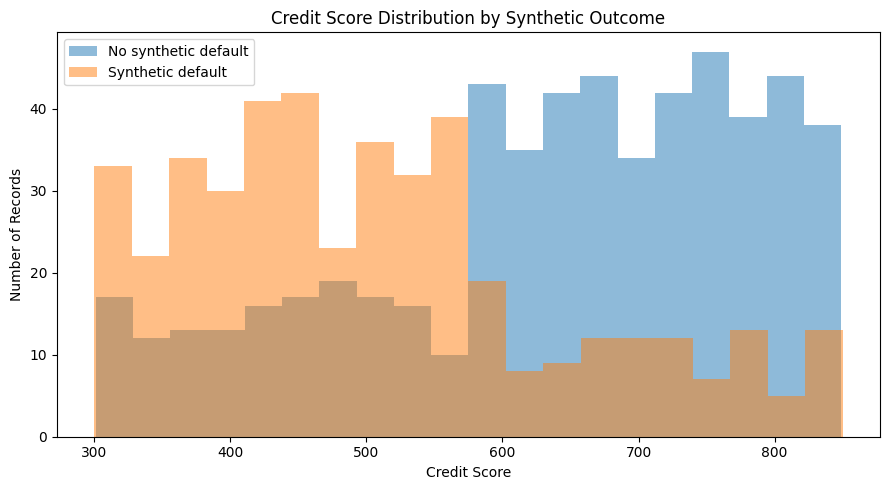

In [ ]:

import matplotlib.pyplot as plt

# PART 8: Credit score distribution

plt.figure(figsize=(9, 5))

for outcome, label in [
    (0, "No synthetic default"),
    (1, "Synthetic default")
]:
    scores = df_clean.loc[
        df_clean["default"] == outcome, "credit_score"
    ]
    plt.hist(scores, bins=20, alpha=0.5, label=label)

plt.title("Credit Score Distribution by Synthetic Outcome")
plt.xlabel("Credit Score")
plt.ylabel("Number of Records")
plt.legend()
plt.tight_layout()
plt.show()


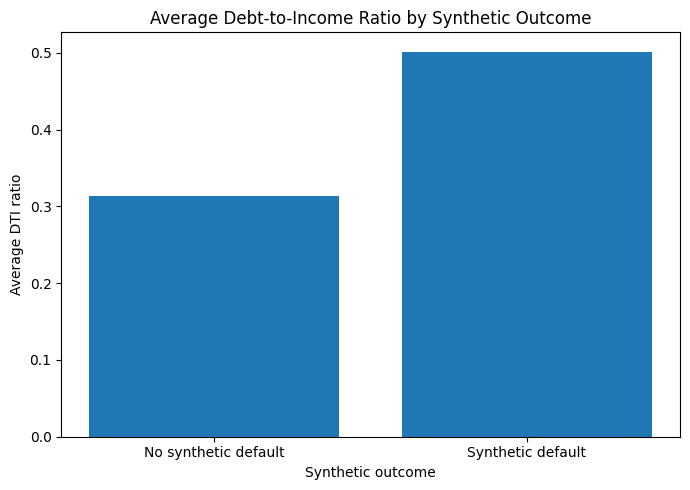

In [ ]:

# PART 9: Average DTI comparison

dti_summary = df_clean.groupby("default")[
    "debt_to_income_ratio"
].mean()

labels = [
    "No synthetic default" if x == 0
    else "Synthetic default"
    for x in dti_summary.index
]

plt.figure(figsize=(7, 5))
plt.bar(labels, dti_summary.values)
plt.title("Average Debt-to-Income Ratio by Synthetic Outcome")
plt.xlabel("Synthetic outcome")
plt.ylabel("Average DTI ratio")
plt.tight_layout()
plt.show()


In [ ]:

# PART 10: Export cleaned dataset

df_clean.to_csv("credit_risk_cleaned.csv", index=False)

print("Cleaned dataset exported successfully.")


Cleaned dataset exported successfully.


##      **Data Limitations and Responsible Interpretation**

- This dataset contains 1,000 synthetically generated borrower records.
- The default outcome was created using predefined illustrative rules based on credit score, debt-to-income ratio, and loan amount relative to annual income.
- Consequently, relationships between these variables and the default label are partly built into the data-generation process.
- The dataset does not represent actual borrowers, actual loan defaults, or a bank's validated credit-risk model.
- The analysis is for educational practice only and must not be used to approve or reject real loan applications.
- Further work would be required to assess real-world data quality, model performance, fairness, and suitability before any practical credit-risk application.

In [ ]:

%pip install -q duckdb

In [ ]:

import duckdb

# Create an in-memory database connection
con = duckdb.connect(database=":memory:")

# Register the cleaned pandas DataFrame
con.register("cleaned_data", df_clean)

# Create a SQL table from the DataFrame
con.execute("""
    CREATE OR REPLACE TABLE loans AS
    SELECT * FROM cleaned_data
""")

# Check that the data loaded correctly
result = con.execute("""
    SELECT COUNT(*) AS total_records
    FROM loans
""").df()

display(result)


,total_records
0,1000


In [ ]:

query = """
SELECT *
FROM loans
LIMIT 10;
"""

display(con.execute(query).df())


,customer_id,age,annual_income,credit_score,employment_years,loan_amount,debt_to_income_ratio,default
0,1,59,879290,608,20,524797,0.10,0
1,2,49,699097,587,16,183763,0.54,0
2,3,35,849789,606,29,627248,0.32,0
3,4,63,1396632,848,9,895820,0.63,1
4,5,28,1262636,651,10,47601,0.51,0
5,6,41,1986921,611,21,436236,0.61,0
6,7,59,1725848,358,29,164227,0.24,0
7,8,39,1767121,334,8,749479,0.53,1
8,9,43,1029735,744,8,717137,0.23,0
9,10,31,1438855,392,23,306854,0.71,1


In [ ]:

query = """
SELECT
    COUNT(*) AS total_records,
    SUM("default") AS synthetic_defaults,
    COUNT(*) - SUM("default") AS non_defaults,
    ROUND(
        100.0 * SUM("default") / COUNT(*),
        2
    ) AS synthetic_default_rate_pct
FROM loans;
"""

display(con.execute(query).df())


,total_records,synthetic_defaults,non_defaults,synthetic_default_rate_pct
0,1000,442.0,558.0,44.2


In [ ]:

query = """
SELECT
    CASE
        WHEN credit_score < 580 THEN 'Below 580'
        WHEN credit_score < 670 THEN '580-669'
        WHEN credit_score < 740 THEN '670-739'
        ELSE '740 and above'
    END AS credit_score_band,
    COUNT(*) AS borrower_count,
    SUM("default") AS synthetic_defaults,
    ROUND(
        100.0 * SUM("default") / COUNT(*), 2
    ) AS synthetic_default_rate_pct
FROM loans
GROUP BY credit_score_band
ORDER BY
    CASE credit_score_band
        WHEN 'Below 580' THEN 1
        WHEN '580-669' THEN 2
        WHEN '670-739' THEN 3
        ELSE 4
    END;
"""

display(con.execute(query).df())


,credit_score_band,borrower_count,synthetic_defaults,synthetic_default_rate_pct
0,Below 580,494,340.0,68.83
1,580-669,166,31.0,18.67
2,670-739,134,33.0,24.63
3,740 and above,206,38.0,18.45


In [ ]:

query = """
SELECT
    CASE
        WHEN debt_to_income_ratio < 0.20 THEN 'Below 20%'
        WHEN debt_to_income_ratio < 0.40 THEN '20%-39%'
        WHEN debt_to_income_ratio < 0.60 THEN '40%-59%'
        ELSE '60% and above'
    END AS dti_band,
    COUNT(*) AS borrower_count,
    SUM("default") AS synthetic_defaults,
    ROUND(
        100.0 * SUM("default") / COUNT(*), 2
    ) AS synthetic_default_rate_pct
FROM loans
GROUP BY dti_band
ORDER BY
    CASE dti_band
        WHEN 'Below 20%' THEN 1
        WHEN '20%-39%' THEN 2
        WHEN '40%-59%' THEN 3
        ELSE 4
    END;
"""

display(con.execute(query).df())


,dti_band,borrower_count,synthetic_defaults,synthetic_default_rate_pct
0,Below 20%,203,51.0,25.12
1,20%-39%,299,55.0,18.39
2,40%-59%,278,163.0,58.63
3,60% and above,220,173.0,78.64


In [ ]:

query = """
SELECT
    customer_id,
    annual_income,
    loan_amount,
    ROUND(
        1.0 * loan_amount / annual_income, 2
    ) AS loan_to_income_ratio,
    credit_score,
    debt_to_income_ratio,
    "default" AS synthetic_default
FROM loans
WHERE loan_amount > annual_income * 0.50
ORDER BY loan_to_income_ratio DESC
LIMIT 20;
"""

display(con.execute(query).df())


,customer_id,annual_income,loan_amount,loan_to_income_ratio,credit_score,debt_to_income_ratio,synthetic_default
0,950,209078,831608,3.98,781,0.63,1
1,562,232733,914855,3.93,535,0.56,1
2,156,213224,803493,3.77,318,0.28,1
3,74,264772,955106,3.61,583,0.66,1
4,318,235954,850626,3.61,403,0.56,1
5,713,248874,895946,3.60,699,0.74,1
6,502,266150,934921,3.51,698,0.30,0
7,997,283186,985811,3.48,489,0.47,1
8,355,251226,857721,3.41,728,0.72,1
9,470,277454,939565,3.39,428,0.20,1



## SQL Analysis — Initial Findings

- Calculated the overall synthetic default rate using SQL.
- Grouped records into credit-score bands and compared their synthetic default rates.
- Grouped records by debt-to-income ratio and compared the resulting rates.
- Identified records with loan amounts exceeding 50% of annual income.
- Practised aggregate functions, conditional grouping, filtering, sorting, and calculated ratios.

### Limitations

All findings are based on synthetic data. Default labels were generated using predefined rules, so observed relationships are not independent evidence of real-world credit risk.
